# **Forecasting and Explaining Marine Heatwaves**

This notebook presents the code of the internship carried out at Mercator Ocean International, in collaboration with the DISCO team of the LAAS-CNRS. It aims to forecast the severity of marine heatwaves in the North Atlantic 5 days ahead with a U-Net, and to explain these forecasts with LIME in order to identify which ocean variables the model uses (and try to understand the drivers of these events).



In [1]:
import io, time, base64, os, json, urllib.request, urllib.parse, numpy as np, torch, torch.nn as nn
import torch.nn.functional as F
import matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, clear_output, HTML
import xarray as xr
from IPython.display import Image
import os
import torch

from sklearn.linear_model import RidgeCV
from dataclasses import dataclass
from scipy import ndimage
import pandas as pd

import copernicusmarine as cm

print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")

print("ça marche")

True NVIDIA RTXA6000-48Q


In [2]:
print(torch.version.cuda)

12.1



## Building the dataset: severity and explanatory variables

This cell builds `ds_total`, the dataset used in the rest of the notebook: daily data from 2015 to 2023 over the North Atlantic study area (30°N–50°N, 50°W–33°W). The climatology and temperature anomalies files were provided by a colleague at Mercator Ocean. 

1. **Temperature anomaly.** Loads the yearly files `anom_<year>_glorys12_l00.nc` (variable `ta`, the anomaly $T - T_{clim}$ relative to the 1993–2022 climatology), keeps the study area and concatenates the years.
2. **Denominator.** Reads the climatology $T_{clim}$ (`thetao_mean`) and the 90th percentile $P90$ (`thetao_pct`), crops them to the study area and computes $P90 - T_{clim}$ for each grid point and each day of the year, then maps it onto every day of the period.
3. **Severity.** Computes $S = \dfrac{T - T_{clim}}{P90 - T_{clim}}$.
4. **Explanatory variables.** Downloads the surface fields `mlotst`, `uo`, `vo`, `zos`, `thetao` and `so` from the daily GLORYS12 reanalysis (Copernicus Marine), over a larger box, then crops them to the study area.
5. **Merge.** Joins severity and explanatory variables in `ds_total`, on the grid and the dates of the severity (`join="left"`).

In [ ]:
DATA_DIR = "/path/to/data"

ANOM_FILE_TEMPLATE = f"{DATA_DIR}/anom/clim_1993-2022/anom_{{year}}_glorys12_l00.nc"
CLIM_FILE          = f"{DATA_DIR}/clim/clim_temp/GLORYS12V1-1993-2022_alldays_gridT_level00_pgs.nc"

# Spatial domain (North Atlantic small zone)
lat_min, lat_max = 30, 50
lon_min, lon_max = -50, -33

# Time range for anomalies
years_range = range(2015, 2024)

def trim_year_and_region_anom(ds):
    """Extracts the specific year based on file source and trims to the spatial domain."""
    source_str = ds.encoding.get("source", "")
    match = re.search(r"(\d{4})_glorys12", source_str)
    if match:
        year = int(match.group(1))
        ds = ds.sel(time=slice(f"{year}-01-01", f"{year}-12-31"))
    
    ds = ds.sel(latitude=slice(lat_min, lat_max), longitude=slice(lon_min, lon_max))
    return ds

def trim_region_int(ds):
    """Trims spatial domain for climatology or intermediate datasets."""
    return ds.sel(latitude=slice(lat_min, lat_max), longitude=slice(lon_min, lon_max))

paths_anom = [ANOM_FILE_TEMPLATE.format(year=y) for y in years_range]

ds_anom = xr.open_mfdataset(
    paths_anom,
    preprocess=trim_year_and_region_anom,
    combine="nested", 
    concat_dim="time",
    parallel=True, 
    chunks={"time": -1},
)

ds_clim = xr.open_dataset(CLIM_FILE)

da_climat = trim_region_int(ds_clim['thetao_mean'])
da_pct    = trim_region_int(ds_clim['thetao_pct'])
da_denom  = da_pct - da_climat

# Align climatology denominator with day-of-year coordinates
da_denom_doy = da_denom.assign_coords(
    dayofyear=da_denom['time'].dt.dayofyear
).swap_dims({'time': 'dayofyear'}).drop_vars('time')

num = ds_anom['ta']
doy = num['time'].dt.dayofyear

# Map climatology/percentile day-by-day over the entire multi-year period
da_denom_full = da_denom_doy.sel(dayofyear=doy)

# Compute marine heatwave severity index (S)
da_severity_all = num / da_denom_full
ds_severity_all = da_severity_all.to_dataset(name='severity')


# We extract the explanatory variables using Copernicus API
ds_exp = cm.open_dataset(
    dataset_id="cmems_mod_glo_phy_my_0.083deg_P1D-m",
    variables=["mlotst", "uo", "vo", "zos", "thetao", "so"],
    minimum_longitude=-80,
    maximum_longitude=-10,
    minimum_latitude=0,
    maximum_latitude=70,
    start_datetime="2015-01-01T00:00:00",
    end_datetime="2023-12-31T00:00:00",
    minimum_depth=0.49402499198913574,
    maximum_depth=0.49402499198913574,
)

ds_exp = trim_region_int(ds_exp)

# Final dataset combining severity and physical explanatory variables
ds_total = xr.merge([ds_severity_all, ds_exp], join="left")

In [2]:
# open the dataset 
taille_octets = os.path.getsize('/home/onyxia/work/mhw-internship/ds_total.nc')
taille_go = taille_octets / (1024**3)
print(f" Size on Edito: {taille_go:.2f} GB ({taille_octets} bytes)")
ds_total = xr.open_dataset('/home/onyxia/work/mhw-internship/ds_total.nc')

 Size on Edito: 2.42 GB (2594436892 bytes)


In [4]:
print(ds_total)

<xarray.Dataset> Size: 8GB
Dimensions:    (time: 3282, depth: 1, latitude: 241, longitude: 205, quantile: 1)
Coordinates:
  * time       (time) datetime64[ns] 26kB 2015-01-01 2015-01-02 ... 2023-12-26
    dayofyear  (time) int64 26kB ...
  * depth      (depth) float32 4B 0.494
  * latitude   (latitude) float32 964B 30.0 30.08 30.17 ... 49.83 49.92 50.0
  * longitude  (longitude) float32 820B -50.0 -49.92 -49.83 ... -33.08 -33.0
  * quantile   (quantile) float64 8B 0.9
Data variables:
    severity   (time, depth, latitude, longitude, quantile) float32 649MB ...
    mlotst     (time, latitude, longitude) float64 1GB ...
    uo         (time, depth, latitude, longitude) float64 1GB ...
    vo         (time, depth, latitude, longitude) float64 1GB ...
    zos        (time, latitude, longitude) float64 1GB ...
    thetao     (time, depth, latitude, longitude) float64 1GB ...
    so         (time, depth, latitude, longitude) float64 1GB ...


In [7]:
# Statistical information on severity

da = ds_total['mlotst']
n_time = da.sizes['time']
batch_size = 200     

total_sum, total_sumsq, total_count = 0.0, 0.0, 0
running_min, running_max = np.inf, -np.inf

for start in range(0, n_time, batch_size):
    chunk = da.isel(time=slice(start, start + batch_size)).compute()   # charge SEULEMENT ce morceau
    vals = chunk.values
    valid = ~np.isnan(vals)

    total_sum += np.nansum(vals)
    total_sumsq += np.nansum(vals ** 2)
    total_count += int(valid.sum())
    if valid.any():
        running_min = min(running_min, float(np.nanmin(vals)))
        running_max = max(running_max, float(np.nanmax(vals)))

    # print(f"batch {start}-{min(start + batch_size, n_time)} traité ({total_count} valeurs valides cumulées)")

mean_val = total_sum / total_count
std_val = np.sqrt(total_sumsq / total_count - mean_val ** 2)

print(f"Mean : {mean_val:.4f}")
print(f"Standard deviation : {std_val:.4f}")
print(f"Min : {running_min:.4f}")
print(f"Max : {running_max:.4f}")

Mean : 54.0821
Standard deviation : 60.6240
Min : 0.0000
Max : 846.4309


In [3]:
VAR_INFO = {
    # nom_var : (nom_affiché, cmap, a_une_dim_depth)
    "severity": ("MHW severity", "YlOrRd", False),
    "zos":      ("SSH",           "viridis", False),
    "mlotst":   ("MLD",           "viridis", False),
    "thetao":   ("Temperature",   "coolwarm", False),
    "so":       ("Salinity",      "viridis", False),
    "uo":       ("Current u",     "RdBu", False),
    "vo":       ("Current v",     "RdBu", False)}

In [4]:
def load_data_from_ds(ds):
    ds = ds.squeeze(drop=True)
    ocean = np.isfinite(ds["severity"].isel(time=0).values)
    print(ocean.shape)
    H, W = ocean.shape
    arrays = {v: ds[v] for v in VAR_INFO}
    nlev = ds["thetao"].sizes["depth"] if "depth" in ds["thetao"].dims else 1
    return dict(arrays=arrays, lat=ds["latitude"].values, lon=ds["longitude"].values,
                depths=ds["thetao"]["depth"].values if "depth" in ds["thetao"].dims else np.array([0.0]),
                dates=ds["time"].values, H=H, W=W, ocean=ocean, T=ds.sizes["time"], nlev=nlev)


def fields_for(input_vars, n_levels):
    f = []
    for v in input_vars:
        f += [(v, L) for L in range(n_levels)] if VAR_INFO[v][2] else [(v, None)]
    return f

In [8]:
def build(data, target, extra_vars, n_levels, years, device=None):
    input_vars = [target] + [v for v in extra_vars if v != target]
    fields = fields_for(input_vars, n_levels)
    if (target, 0) not in fields and (target, None) not in fields:
        fields = [(target, 0)] + fields
    ti = fields.index((target, 0)) if (target, 0) in fields else fields.index((target, None))
    T = data["T"]; ocean = data["ocean"]
    yrs = data["dates"].astype("datetime64[D]").astype("datetime64[Y]").astype(int) + 1970
    exam_year = int(yrs.max())
    exam_start = int(np.argmax(yrs >= exam_year))
    train_start = int(np.argmax(yrs >= exam_year - years))
    sl = slice(train_start, T)
    chans, mus, sds = [], [], []
    for (v, L) in fields:
        da = data["arrays"][v].isel(time=sl) if L is None else data["arrays"][v].isel(time=sl, depth=L)
        a = da.astype("float32").values          # <- lecture disque ici seulement, sur la tranche utile
        m = np.nanmean(a[:, ocean]); s = np.nanstd(a[:, ocean]) + 1e-6
        chans.append(np.nan_to_num((a - m) / s, nan=0.0).astype("float32")); mus.append(m); sds.append(s)
    X = torch.tensor(np.stack(chans, 1))
    dts = data["dates"][sl].astype("datetime64[D]")
    doy = (dts - dts.astype("datetime64[Y]")).astype("timedelta64[D]").astype(int)
    ang = doy / 365.0 * 2 * np.pi
    seas = torch.tensor(np.stack([np.sin(ang), np.cos(ang)], 1).astype("float32"))
    return dict(X=X, seas=seas, fields=fields, ti=ti, target=target, mus=np.array(mus), sds=np.array(sds),
                mask=torch.tensor(ocean[None, None].astype("float32")), pe=exam_start - train_start, ocean=ocean,
                C=len(fields), exam_year=exam_year, train_from=int(yrs[train_start]))

In [5]:
#Build but correction: we compute the statistics only on training set

def build_corr(data, target, extra_vars, n_levels, years, device=None):
    input_vars = [target] + [v for v in extra_vars if v != target]
    fields = fields_for(input_vars, n_levels)
    if (target, 0) not in fields and (target, None) not in fields:
        fields = [(target, 0)] + fields
    ti = fields.index((target, 0)) if (target, 0) in fields else fields.index((target, None))
    T = data["T"]; ocean = data["ocean"]
    yrs = data["dates"].astype("datetime64[D]").astype("datetime64[Y]").astype(int) + 1970
    exam_year = int(yrs.max())
    exam_start = int(np.argmax(yrs >= exam_year))
    train_start = int(np.argmax(yrs >= exam_year - years))
    sl = slice(train_start, T)
    chans, mus, sds = [], [], []
    for (v, L) in fields:
        da = data["arrays"][v].isel(time=sl) if L is None else data["arrays"][v].isel(time=sl, depth=L)
        a = da.astype("float32").values          # <- lecture disque ici seulement, sur la tranche utile
        m = np.nanmean(a[:exam_start - train_start, ocean]); s = np.nanstd(a[:exam_start - train_start, ocean]) + 1e-6
        chans.append(np.nan_to_num((a - m) / s, nan=0.0).astype("float32")); mus.append(m); sds.append(s)
    X = torch.tensor(np.stack(chans, 1))
    dts = data["dates"][sl].astype("datetime64[D]")
    doy = (dts - dts.astype("datetime64[Y]")).astype("timedelta64[D]").astype(int)
    ang = doy / 365.0 * 2 * np.pi
    seas = torch.tensor(np.stack([np.sin(ang), np.cos(ang)], 1).astype("float32"))
    return dict(X=X, seas=seas, fields=fields, ti=ti, target=target, mus=np.array(mus), sds=np.array(sds),
                mask=torch.tensor(ocean[None, None].astype("float32")), pe=exam_start - train_start, ocean=ocean,
                C=len(fields), exam_year=exam_year, train_from=int(yrs[train_start]))

In [6]:
def _blk(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                         nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU())

class Net(nn.Module):
    """Small residual U-Net: encoder downsamples (summarize) → bottleneck → decoder upsamples
    with skip connections (restore detail). Predicts the change in the target field."""
    def __init__(s, Cin, ti, width, depth):
        super().__init__(); s.ti = ti
        s.levels = max(2, min(3, depth))                  # U-Net depth: 2 or 3 levels (grid is 36x72)
        ch = [width * (2 ** k) for k in range(s.levels + 1)]
        s.enc = nn.ModuleList(); prev = Cin + 2
        for k in range(s.levels): s.enc.append(_blk(prev, ch[k])); prev = ch[k]
        s.bott = _blk(ch[s.levels - 1], ch[s.levels])
        s.dec = nn.ModuleList(); prev = ch[s.levels]
        for k in reversed(range(s.levels)): s.dec.append(_blk(prev + ch[k], ch[k])); prev = ch[k]
        s.out = nn.Conv2d(ch[0], 1, 3, padding=1); s.pool = nn.MaxPool2d(2)
    def forward(s, x):                       # x: (N, Cin+2, H, W); predicts only the target channel
        h = x; skips = []
        for enc in s.enc: h = enc(h); skips.append(h); h = s.pool(h)
        h = s.bott(h)
        for dec, skip in zip(s.dec, reversed(skips)):
            h = F.interpolate(h, size=skip.shape[-2:], mode="bilinear", align_corners=False)
            h = dec(torch.cat([h, skip], 1))
        return x[:, s.ti:s.ti + 1] + s.out(h)

def _sp(seas, day, N, H, W, dev): return seas.to(dev)[day].view(N, 2, 1, 1).expand(N, 2, H, W)

In [7]:
# Train a first model, M1, that makes the hypothesis that the state of the ocean at day d+i = state at day d

def train_M1(data, prep, width, depth, lead, epochs=20, lr=0.003, K=4, device=None, on_epoch=None, batch=16):
    dev = device or ("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
    torch.manual_seed(0)
    X = prep["X"].to(dev); seas = prep["seas"]; m = prep["mask"].to(dev); ti = prep["ti"]; H, W = data["H"], data["W"]
    net = Net(prep["C"], ti, width, depth).to(dev); opt = torch.optim.Adam(net.parameters(), lr); hist = []
    def kstep_loss(b): # calcule l'erreur du mod sur K pas de temps dans le futur : multi-step loss for a batch of starts : permet d'éviter une explosion des erreurs sur le long terme
        base = X[b]; cur = base[:, ti:ti + 1]; loss = 0
        for step in range(1, K + 1):
            fld = base.clone(); fld[:, ti:ti + 1] = cur
            pred = net(torch.cat([fld, _sp(seas, b + (step - 1), len(b), H, W, dev)], 1)).clamp(-4, 4)
            loss = loss + (((pred - X[b + step, ti:ti + 1]) * m) ** 2).mean(); cur = pred
        return loss / K
    #pe : index of the limit training-validation
    starts = np.arange(0, prep["pe"] - K - 1)#create a list of all the possible starting idexes to create the training sequences
    vhist = [] #list that stocks the validation score at the end of each epoch
    t0 = time.time()
    vstarts = np.linspace(prep["pe"], len(X) - K - 1, min(96, max(2, len(X) - K - 1 - prep["pe"]))).astype(int) # on choisit un petit nb de pts régulièrement espacés dans le futur du début de la période de validation (prep["pe"])jusqu'à la fin d dataset (len(X)-K-1). On prend entre 2 et 96 pts
    vb = torch.tensor(vstarts).to(dev) #envoie la liste d'indices de validation sur la carte graphique
    #on initialise la sauvegarde du meilleur modèle
    best_val = float("inf") # Première meilleure val est infini donc on sera forcément plus petit
    best_state = None
    best_ep = 1 #compteur pour se rappeler à quelle époque le meilleur état a été atteint
    for ep in range(epochs): #1 epoche = un passage complet du modèle sur les données d'entrainement
        
        #print("debut_epoch")
        
        net.train() #on passe en mode entrainement : active des fonctionnalités spécifiques du réseau
        order = np.random.default_rng(ep).permutation(starts) #mélange aléatoirement la liste des positions de départ
        run = nb = 0 #run accumule la somme des erreurs de l'époque, nb compte le nb de lots (batches) traités
        for i in range(0, len(order), batch): #on fait de l'apprentissage par petit lot
            b = torch.tensor(order[i:i + batch]).to(dev) #prend un paquet de 16 indices de départ, le transforme en tensor et l'envoie sur la carte graphique
            opt.zero_grad() # on efface la mémoire des calculs précédents (important with Pytorch)
            loss = kstep_loss(b) # on calcule la fonction perte
            loss.backward() # rétropropagation : remonte tout le réseau à l'envers pour calculer le gradient de chaque paramètre => de combien et dans quel sens chaque poids du réseau doit changer pour réduire l'erreur ?
            nn.utils.clip_grad_norm_(net.parameters(), 1.0) # limite la force max de correction à 1
            opt.step() #L'optimiseur Adam applique la modif sur les poids du réseau
            run += float(loss.detach()); nb += 1 # on convertit l'erreur en chiffre simple pour couper le lien avec le graphe de calcul et libérer de la mémoire
            
        hist.append(run / nb) # on calcule l'erreur moyenne d'entrainement pour toute l'époque et on l'ajoute à l'historique général hist
        
        #print("fin_epoch")
        
        net.eval() #on signal qu'on arrête l'entrainement et on passe en mode validation
        with torch.no_grad(): vhist.append(float(kstep_loss(vb)))   # validation: held-out, never trained on
        if vhist[-1] < best_val:                                    # remember the BEST checkpoint
            best_val = vhist[-1]; best_ep = ep + 1
            best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
        if on_epoch: on_epoch(ep + 1, epochs, hist, vhist, net, dev)
    if best_state is not None: net.load_state_dict(best_state)      # keep the best (not the last) - early stopping
    net.eval()
    return dict(net=net, dev=dev, loss=hist, val=vhist, best_epoch=best_ep, seconds=time.time() - t0,
                width=width, depth=depth, nparams=sum(p.numel() for p in net.parameters()))

In [8]:
# Now  que the network is trained, this function does a real forecast at "lead" days

def _rollout_M1(net, dev, X, seas, ti, starts, lead, H, W): 
    base = X[starts].to(dev); cur = base[:, ti:ti + 1]; persist = cur.clone(); st = torch.tensor(starts).to(dev); outs = []
    with torch.no_grad():
        for k in range(lead):
            fld = base.clone(); fld[:, ti:ti + 1] = cur
            cur = net(torch.cat([fld, _sp(seas, st + k, len(starts), H, W, dev)], 1)).clamp(-4, 4); outs.append(cur)
    return outs, persist

In [9]:
# Computes the skill score (1-ratio of RMSE)

def skill_score_M1(data, prep, result, lead, n_starts=80): # print a score that compares the forecast to M0, the persistence
    dev = result["dev"]; X = prep["X"]; m = prep["mask"].to(dev); H, W = data["H"], data["W"]; ti = prep["ti"]
    starts = np.linspace(prep["pe"], len(X) - lead - 1, n_starts).astype(int)
    outs, persist = _rollout(result["net"], dev, X, prep["seas"], ti, starts, lead, H, W)
    denom = m.sum() * len(starts); sk = [] ; rmse_mod=[]; rmse_persis=[]
    for k in range(lead):
        truth = X[starts + k + 1, ti:ti + 1].to(dev)
        mr = float(torch.sqrt((((outs[k] - truth) * m) ** 2).sum() / denom))
        pr = float(torch.sqrt((((persist - truth) * m) ** 2).sum() / denom))
        sk.append(100 * (1 - mr / pr))
        rmse_mod.append(mr)
        rmse_persis.append(pr)
    return np.arange(1, lead + 1), np.array(sk), rmse_mod, rmse_persis

In [21]:
data = load_data_from_ds(ds_total)
prep = build(data, target="severity", extra_vars=["mlotst", "so", "thetao", "uo", "vo", "zos"],
             n_levels=1, years=3)   # ex: 3 years of training before the exam year

(241, 205)


In [10]:
#version corrigée
data = load_data_from_ds(ds_total)
prep = build_corr(data, target="severity", extra_vars=["mlotst", "so", "thetao", "uo", "vo", "zos"],
             n_levels=1, years=3)   # ex: 3 ans d'entraînement avant l'année-examen

(241, 205)


We train a first model, M1.
Inputs: Severity and state of the ocean (explanatory variables) at day 0
Structure: autoregressive (only on severity) U-Net model 
Output: Severity K (we chose K=5) days after the start.

The loss function is optimized for K days after the start day so that it doesn't explode after the first forecast

In [11]:
result_M1 = train_M1(data, prep, width=24, depth=2, lead=5, epochs=20, K=5)   # K=5 : la loss d'entraînement déroule 5 pas

pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


In [12]:
horizons, skill, rmse_M1, rmse_M0 = skill_score_M1(data, prep, result_M1, lead=5)   # skill[4] = score à J+5

We compare our results for each day of the forecast using the Root Mean Square Error and we compare our results to the model M0, which is based on the persistence hypothesis (severity at day 5 = severity at day 0). 

In [24]:
print("RMSE of M0: ", rmse_M0)
print("RMSE of M1: ", rmse_M1)
print("Skill score : ",horizons, skill)

Skill score :  [1 2 3 4 5] [13.3125402  18.68119823 19.73770173 19.58296846 19.14231105]
RMSE of the model:  [0.2568022608757019, 0.3847079873085022, 0.4725308418273926, 0.5436420440673828, 0.5994253158569336]
RMSE of the persistence:  [0.2962392270565033, 0.4730861485004425, 0.5887332558631897, 0.6760284900665283, 0.7413337230682373]


In [13]:
# With correction
print("RMSE of M0: ", rmse_M0)
print("RMSE of M1: ", rmse_M1)
print("Skill score : ",horizons, skill)

Skill score :  [1 2 3 4 5] [11.24676696 18.1315625  19.86329948 19.9680563  19.70328975]
RMSE of the model:  [0.26533010601997375, 0.3908557593822479, 0.4761127233505249, 0.5459943413734436, 0.6007189154624939]
RMSE of the persistence:  [0.2989526093006134, 0.47741934657096863, 0.5941256880760193, 0.6822205185890198, 0.7481239438056946]


We observe that our model M1 improves the forecast compared to M0 (at day 5 we improve 19.70 % )

In [25]:

# --- Parameters ---
lead = 5  
dev = result_M1["dev"]
net = result_M1["net"]
X = prep["X"]
seas = prep["seas"]
ti = prep["ti"]
m_mask = prep["mask"].to(dev)   # mask ocean (1) / ground (0)
H, W = data["H"], data["W"]

# We choose a start day in the validation period (after["pe"]),
# to evaluate on data that the model did not see during training
t0 = prep["pe"] + 50          # Starting day
target_day = t0 + lead        # Forecasted day 

assert target_day < len(X), "t0 too large: we exceed the end of the dataset"

# --- forecast by rollout 
outs, persist = _rollout_M1(net, dev, X, seas, ti, starts=[t0], lead=lead, H=H, W=W)
pred_std = outs[-1][0, 0].cpu().numpy()          # last step of the rollout = day t0+lead, still standardised


truth_std = X[target_day, ti].cpu().numpy()       


mu, sd = prep["mus"][ti], prep["sds"][ti]
pred_severity_persis = pred_std * sd + mu
truth_severity = truth_std * sd + mu

ocean = data["ocean"]
pred_severity_persis = np.where(ocean, pred_severity_persis, np.nan)
truth_severity = np.where(ocean, truth_severity, np.nan)

# For the display, we select the points where severity S>1 and we put the severity of all the other points at 0. 
# (The goal of this is to visually compare the zones where S>1)
pred_mhw2=np.where(pred_severity_persis<=1, 0, pred_severity_persis)
truth_mhw=np.where(truth_severity<=1, 0, truth_severity)
vmin, vmax = 0, 5

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im0 = axes[0].imshow(truth_mhw, cmap="YlOrRd", vmin=vmin, vmax=vmax, origin="lower")
axes[0].set_title(f"Real severity — day {target_day}")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(pred_mhw2, cmap="YlOrRd", vmin=vmin, vmax=vmax, origin="lower")
axes[1].set_title(f"M1 forecast — day {target_day}")
plt.colorbar(im1, ax=axes[1], fraction=0.046)
plt.savefig("comparaison_severity_M1.png", dpi=150, bbox_inches="tight")

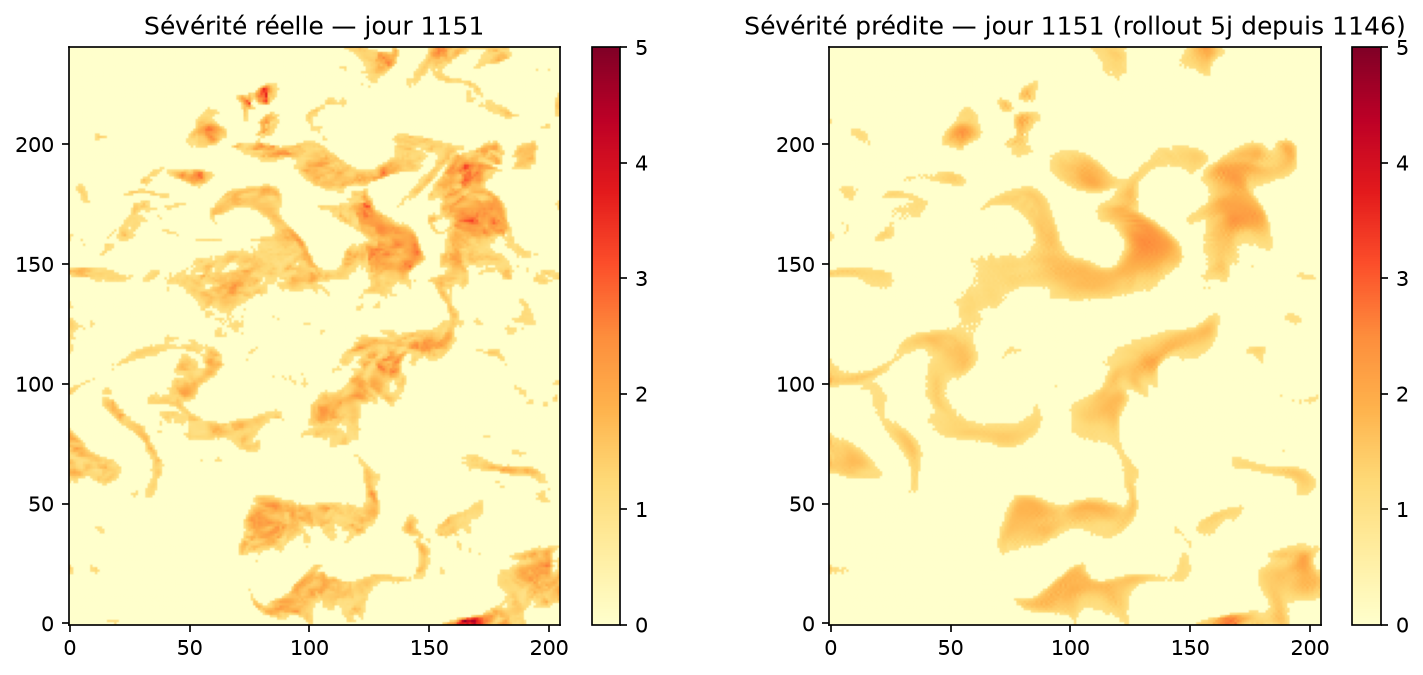

In [27]:
Image("comparaison_severity_M1.png")

In [23]:
plt.close(fig)

=> Our first model M1 captures the main form of the events, but it seems like it mainly diffuses the severity given at t0.

We now train a second model, M2, whose inputs is also the severity variables at day 0 and the explanatory variables at day 0, but also the explanatory variables at days 1, 2, 3 and 4. We say that we add oceanic forcing. 
The structure of the neural network stays otherwise the same, and we use the same validation tools : RMSE, skill score and maps comparing our results to the real severity. 

In [26]:
def train_M2(data, prep, width, depth, lead, epochs=20, lr=0.003, K=4, device=None, on_epoch=None, batch=16, true_forcing=True):
    dev = device or ("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
    torch.manual_seed(0)
    X = prep["X"].to(dev); seas = prep["seas"]; m = prep["mask"].to(dev); ti = prep["ti"]; H, W = data["H"], data["W"]
    net = Net(prep["C"], ti, width, depth).to(dev); opt = torch.optim.Adam(net.parameters(), lr); hist = []
    def kstep_loss(b): 
        cur = X[b, ti:ti + 1]; loss = 0
        for step in range(1, K + 1):
            if true_forcing:
                fld = X[b +step - 1].clone()
            else:
                fld = X[b].clone()
            fld[:, ti:ti + 1] = cur
            pred = net(torch.cat([fld, _sp(seas, b + (step - 1), len(b), H, W, dev)], 1)).clamp(-4, 4)
            loss = loss + (((pred - X[b + step, ti:ti + 1]) * m) ** 2).mean(); cur = pred
        return loss / K
    #pe : index of the limit training-validation
    starts = np.arange(0, prep["pe"] - K - 1)
    vhist = [] 
    t0 = time.time()
    vstarts = np.linspace(prep["pe"], len(X) - K - 1, min(96, max(2, len(X) - K - 1 - prep["pe"]))).astype(int) 
    vb = torch.tensor(vstarts).to(dev) 
    
    best_val = float("inf") 
    best_state = None
    best_ep = 1 
    for ep in range(epochs): 
        print("start_epoch")
        net.train() 
        order = np.random.default_rng(ep).permutation(starts) 
        run = nb = 0 
        for i in range(0, len(order), batch): 
            b = torch.tensor(order[i:i + batch]).to(dev) 
            opt.zero_grad() 
            loss = kstep_loss(b) 
            loss.backward() 
            nn.utils.clip_grad_norm_(net.parameters(), 1.0) 
            opt.step() 
            run += float(loss.detach()); nb += 1
            
        hist.append(run / nb) 
        print("end_epoch")
        net.eval() 
        with torch.no_grad(): vhist.append(float(kstep_loss(vb)))   
        if vhist[-1] < best_val:                                    
            best_val = vhist[-1]; best_ep = ep + 1
            best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
        if on_epoch: on_epoch(ep + 1, epochs, hist, vhist, net, dev)
    if best_state is not None: net.load_state_dict(best_state)      
    #print(best_ep)
    net.eval()
    return dict(net=net, dev=dev, loss=hist, val=vhist, best_epoch=best_ep, seconds=time.time() - t0,
                width=width, depth=depth, nparams=sum(p.numel() for p in net.parameters()))

In [27]:
result_M2 = train_M2(data, prep, width=24, depth=2, lead=5, epochs=15, K=5) 

pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


pipoup_debut


pipoup_fin


14


In [28]:
def _rollout_M2(net, dev, X, seas, ti, starts, lead, H, W):
    """
    Variante : la sévérité (canal ti) évolue de façon autoregressive (comme avant),
    mais les AUTRES canaux (SST, salinité, etc.) utilisent leur vraie valeur
    au jour courant simulé, au lieu de rester figés au jour de départ.
    """
    st = torch.tensor(starts).to(dev)
    cur = X[starts, ti:ti + 1].to(dev)   # sévérité initiale (jour t0)
    persist = cur.clone()
    outs = []
    with torch.no_grad():
        for k in range(lead):
            # on récupère les VRAIES données du jour t0+k (pas celles de t0 figées)
            fld = X[np.array(starts) + k].to(dev).clone()
            fld[:, ti:ti + 1] = cur   # seule la sévérité vient de la prédiction précédente
            cur = net(torch.cat([fld, _sp(seas, st + k, len(starts), H, W, dev)], 1)).clamp(-4, 4)
            outs.append(cur)
    return outs, persist

def skill_score_M2(data, prep, result, lead, n_starts=80): #affiche un score qui compare les prévisions au modèle persistance
    dev = result["dev"]; X = prep["X"]; m = prep["mask"].to(dev); H, W = data["H"], data["W"]; ti = prep["ti"]
    starts = np.linspace(prep["pe"], len(X) - lead - 1, n_starts).astype(int)
    outs, persist = _rollout_true_forcing(result["net"], dev, X, prep["seas"], ti, starts, lead, H, W)
    denom = m.sum() * len(starts); sk = [] ; rmse_mod = [] ; rmse_persis = []
    for k in range(lead):
        truth = X[starts + k + 1, ti:ti + 1].to(dev)
        mr = float(torch.sqrt((((outs[k] - truth) * m) ** 2).sum() / denom))
        pr = float(torch.sqrt((((persist - truth) * m) ** 2).sum() / denom))
        sk.append(100 * (1 - mr / pr))
        rmse_mod.append(mr)
        rmse_persis.append(pr)
    return np.arange(1, lead + 1), np.array(sk), np.array(rmse_mod), np.array(rmse_persis)


horizons, skill, rmse_M2, rmse_M0 = skill_score_M2(data, prep, result_M2, lead=5)   # skill[4] = score à J+5
print(horizons, skill)

[1 2 3 4 5] [11.5267704  13.93925856 12.39952598 10.52779981  9.35915178]


In [14]:
horizons, skill, rmse_mod, rmse_persis  = skill_curve_true_forc(data, prep, result_true_forc, lead=5)   # skill[4] = score à J+5

print("Model's RMSE compared to Persistence's RMSE ",rmse_mod, rmse_persis )
print(horizons, skill, rmse_mod, rmse_persis)
X=prep["X"]
ti=prep["ti"]
truth_all = X[:, ti:ti+1][prep["pe"]:]
print("std(S) sur la période de validation:", float(truth_all.std()))
print("RMSE / std = ", float(rmse_mod[4]/truth_all.std()))

Model's RMSE compared to Persistence's RMSE  [0.26274925 0.34544149 0.39689806 0.43886915 0.46720693] [0.29623923 0.47308615 0.58873326 0.67602849 0.74133372]
[1 2 3 4 5] [11.30504312 26.98127149 32.58439929 35.08126433 36.97751625] [0.26274925 0.34544149 0.39689806 0.43886915 0.46720693] [0.29623923 0.47308615 0.58873326 0.67602849 0.74133372]
std(S) sur la période de validation: 1.0216690301895142
RMSE / std =  0.45729774236679077


On observe un rapport $RMSE/std <0.5$, ce qui reste assez satisfaisant. 

In [29]:
horizons, skill, rmse_mod, rmse_persis  = skill_curve_true_forc(data, prep, result_true_forc, lead=5)  
print("Skill score :", horizons, skill)
print("RMSE of the model : ",rmse_mod)
print("RMSE of the persistence : ",rmse_persis )

X=prep["X"]
ti=prep["ti"]
truth_all = X[:, ti:ti+1][prep["pe"]:]
#print("std(S) sur la période de validation:", float(truth_all.std()))
#print("RMSE / std = ", float(rmse_mod[4]/truth_all.std()))

Skill score : [1 2 3 4 5] [11.5267704  26.48004109 31.75601037 33.91929166 35.51621964]
RMSE of the model :  [0.26209241 0.34781274 0.40177506 0.44672441 0.47804001]
RMSE of the persistence :  [0.29623923 0.47308615 0.58873326 0.67602849 0.74133372]


In [38]:
# --- Paramètres ---
lead = 5   # même horizon que ton entraînement (K=5, lead=5)
dev = result_true_forc["dev"]
net = result_true_forc["net"]
X = prep["X"]
seas = prep["seas"]
ti = prep["ti"]
m_mask = prep["mask"].to(dev)   # masque océan (1) / terre (0)
H, W = data["H"], data["W"]

# on choisit un jour de départ dans la période de VALIDATION (après prep["pe"]),
# pour évaluer sur des données que le modèle n'a pas vues en entraînement
t0 = prep["pe"] + 50          # jour de départ, ajuste selon la longueur de ta période de validation
target_day = t0 + lead        # jour prédit / jour de vérité comparé

assert target_day < len(X), "t0 trop grand : dépasse la fin du dataset"

# Prévision par rollout 
outs, persist = _rollout_true_forcing(net, dev, X, seas, ti, starts=[t0], lead=lead, H=H, W=W)
pred_std = outs[-1][0, 0].cpu().numpy()          # dernière étape du rollout = jour t0+lead, encore standardisé


truth_std = X[target_day, ti].cpu().numpy()       


mu, sd = prep["mus"][ti], prep["sds"][ti]
pred_severity = pred_std * sd + mu
truth_severity = truth_std * sd + mu


ocean = data["ocean"]
pred_severity_true_forc = np.where(ocean, pred_severity, np.nan)
truth_severity = np.where(ocean, truth_severity, np.nan)

pred_mhw=np.where(pred_severity_true_forc<=1, 0, pred_severity_true_forc)
truth_mhw=np.where(truth_severity<=1, 0, truth_severity)

vmin, vmax = 0, 5

fig, axes = plt.subplots(1, 3, figsize=(12, 5))

im0 = axes[0].imshow(truth_mhw, cmap="YlOrRd", vmin=vmin, vmax=vmax, origin="lower")
axes[0].set_title(f"Real severity — day {target_day}")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(pred_mhw, cmap="YlOrRd", vmin=vmin, vmax=vmax, origin="lower")
axes[1].set_title(f"Severity forecast — day {target_day}")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

im2 = axes[2].imshow(pred_mhw2, cmap="YlOrRd", vmin=vmin, vmax=vmax, origin="lower")
axes[2].set_title(f"Forecast with persistence — day {target_day}")
plt.colorbar(im0, ax=axes[2], fraction=0.046)

plt.savefig("comparaison_severite_trueforc1.png", dpi=150, bbox_inches="tight")
plt.tight_layout()
plt.show()

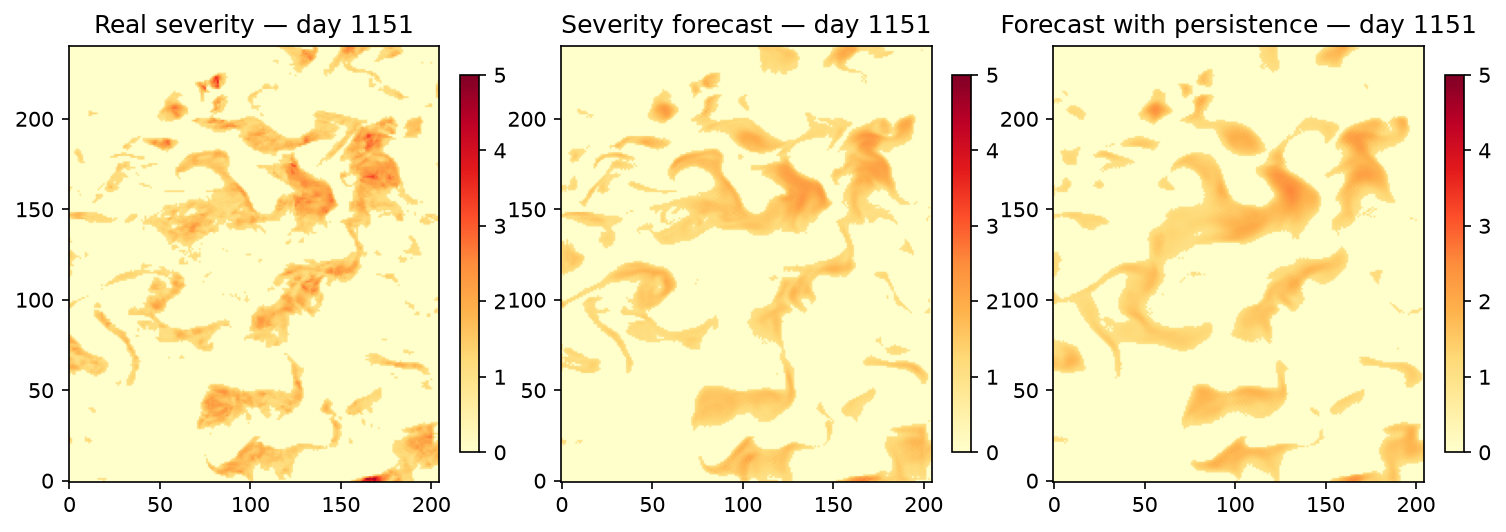

In [39]:
Image("comparaison_severite_trueforc1.png")

In [ ]:
Image("comparaison_severite_trueforc1.png")

In [34]:
# 1. Sélection de TOUTE la période de validation/test
val_start = prep["pe"]
X_val = X[val_start:]  # Garde tous les jours de validation (forme: T, C, H, W)

# 2. Récupération des températures réelles standardisées sur toute la période
# X_val[:, ti] a pour forme (T, H, W)
truth_std_3d = X_val[:, ti].cpu().numpy()

# 3. Dé-standardisation pour obtenir la sévérité 3D sur tous les jours (T, H, W)
mu, sd = prep["mus"][ti], prep["sds"][ti]
truth_severity_3d = truth_std_3d * sd + mu

# 4. Application du masque Océan sur tout le volume 3D
ocean_3d = data["ocean"][None, :, :]  # Étend le masque océan à (1, H, W) pour le broadcasting
truth_severity_3d = np.where(ocean_3d, truth_severity_3d, np.nan)

# 5. Création du masque binaire de dépassement (Sévérité > 1 = Seuil P90 dépassé)
exceedance_3d = (truth_severity_3d > 1) & ocean_3d

# 6. Adaptation des coordonnées temporelles
dates = data["dates"]
time_coords_val = dates[val_start:]
lat_coords = data["lat"]
lon_coords = data["lon"]

REMARQUE : Pour J1, c'est normal qu'on ait exactement la même chose !

0.2179034 2.3212733


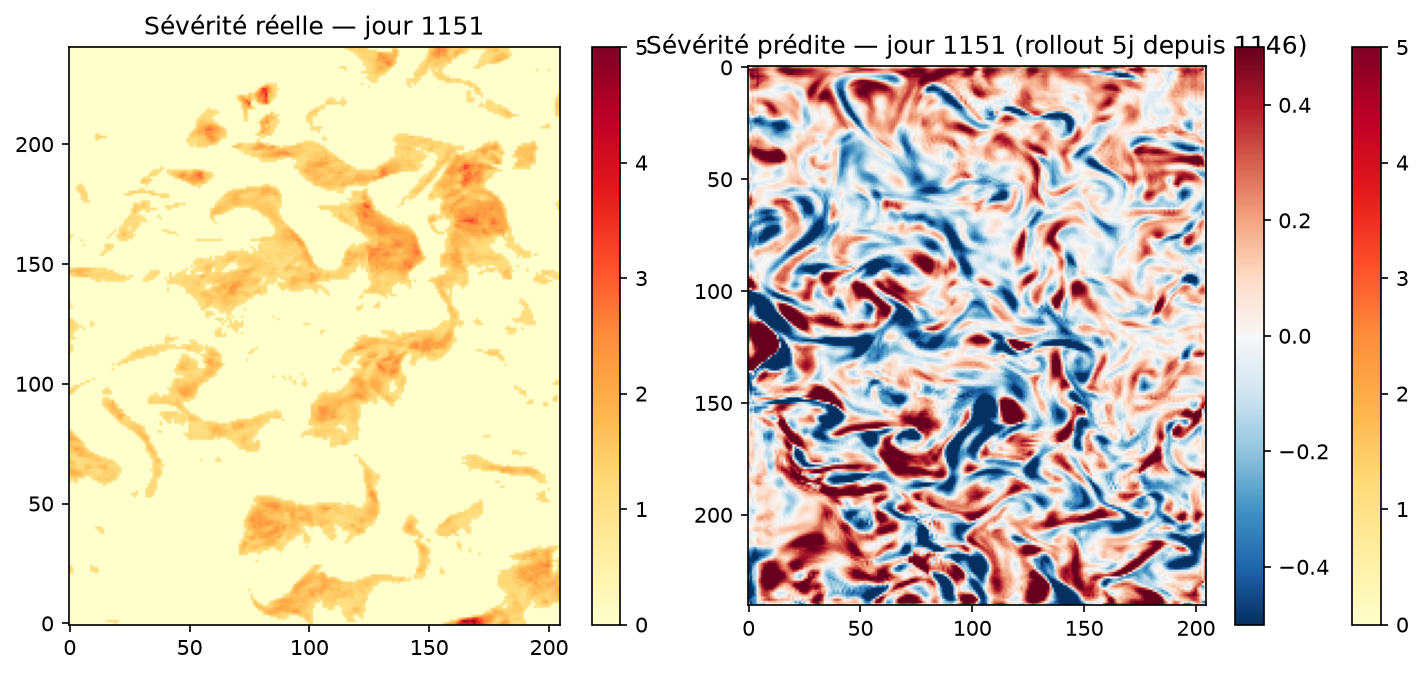

In [28]:
diff = pred_severity_true_forc - pred_severity_persis   # deux prédictions à même t0, lead, mêmes couches
print(np.nanmean(np.abs(diff)), np.nanmax(np.abs(diff)))
plt.imshow(diff, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
plt.colorbar()
plt.savefig("comparaison_true_forc_persis.png", dpi=150, bbox_inches="tight")
Image("comparaison_true_forc_persis.png")

In [30]:
plt.close()

On voit quand même qu'il y a une vraie différence à J+5 entre la prévision réalisée avec la persistance pour les canaux d'entrée, ou le "vrai" état de l'océan. 

Regardons maintenant la comparaison entre la prévision et la réalité (pour les deux prévisions)

0.2257199 2.4150026


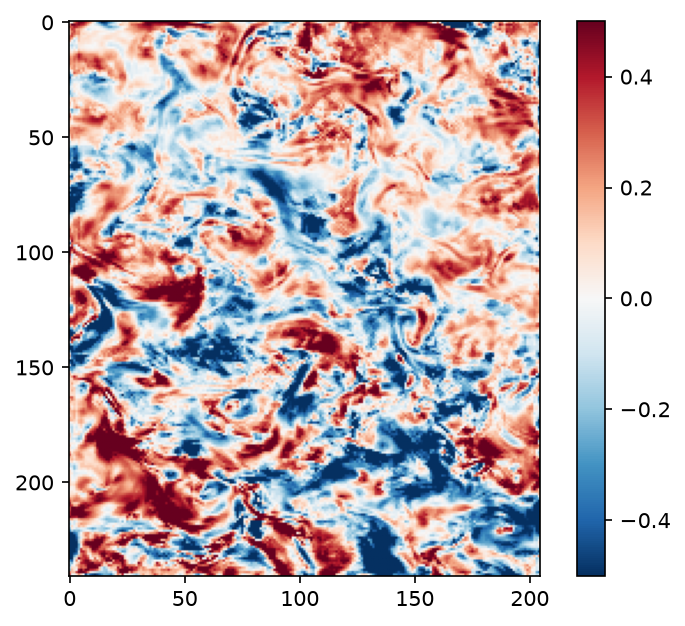

In [34]:
plt.close('all')
diff = pred_severity_true_forc - truth_severity   # deux prédictions à même t0, lead, mêmes couches
print(np.nanmean(np.abs(diff)), np.nanmax(np.abs(diff)))
plt.imshow(diff, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
plt.colorbar()
plt.savefig("comparaison_true_forc_real.png", dpi=150, bbox_inches="tight")
Image("comparaison_true_forc_real.png")


0.2850819 2.93793


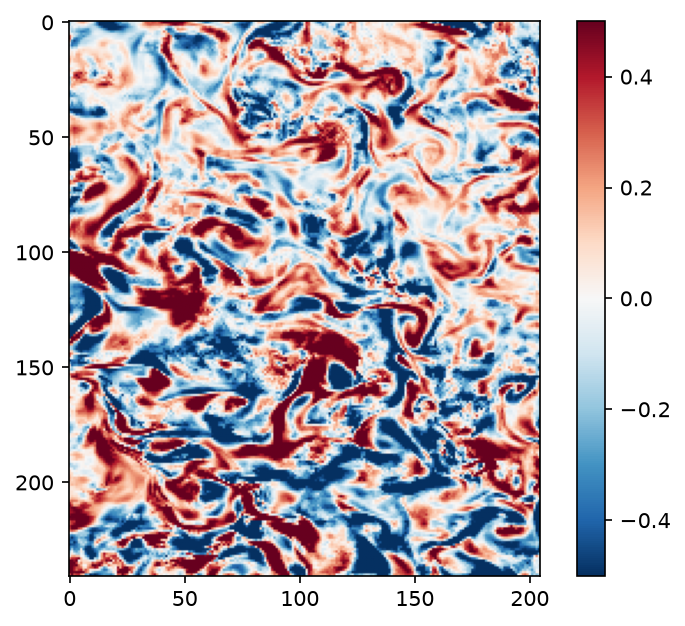

In [35]:
plt.close('all')
diff = pred_severity_persis - truth_severity   # deux prédictions à même t0, lead, mêmes couches
print(np.nanmean(np.abs(diff)), np.nanmax(np.abs(diff)))
plt.imshow(diff, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
plt.colorbar()
plt.savefig("comparaison_persis_real.png", dpi=150, bbox_inches="tight")
Image("comparaison_persis_real.png")


## INTERPRETABILITY 
Je commence par appliquer la méthode LIME (local interpretable model-agnostic explanations). 
Principe : Explainibility method for feature relevance (feature attribution usinf the coefficients of a local linear model). 
* Select your instance of interest for which you want to have an explanation of its black box prediction.
* Perturb your dataset and get the black box predictions for these new points.
* Weight the new samples according to their proximity to the instance of interest.
* Train a weighted, interpretable model on the dataset with the variations.
* Explain the prediction by interpreting the local model.
  (https://christophm.github.io/interpretable-ml-book/lime.html)

In [40]:
#Fonction qui permet de faire du roll_out en choisissant quel paramètre on met en persistence et quel paramètre on met en forçage
#Question : quelle forme a mon forcing_schedule ? -> taille 1->lead je crois, et 

#start_time = time.perf_counter()

def _rollout_flexible(net, dev, X, seas, ti, starts, lead, H, W, _sp,
                       forcing_schedule=None):
    """
    À chaque pas k du rollout, forcing_schedule[k] décide, canal par canal,
    si on utilise le forçage réel du jour t0+k ou la persistance (jour t0).
    forcing_schedule[k] : bool global, ou array booléen de longueur C.
    """
    st = torch.tensor(starts).to(dev)
    base = X[starts].to(dev)
    cur = base[:, ti:ti+1].clone()
    C = base.shape[1]
    if forcing_schedule is None:
        forcing_schedule = [False] * lead
 
    outs = []
    with torch.no_grad():
        for k in range(lead):
            true_day = X[np.array(starts) + k].to(dev)
            sched = forcing_schedule[k]
            if isinstance(sched, (bool, np.bool_)):
                mask = torch.full((C,), bool(sched), dtype=torch.bool, device=dev)
            else:
                mask = torch.as_tensor(sched, dtype=torch.bool, device=dev)
            mask = mask.view(1, C, 1, 1)
            fld = torch.where(mask, true_day, base)
            fld[:, ti:ti + 1] = cur
            cur = net(torch.cat([fld, _sp(seas, st + k, len(starts), H, W, dev)], 1)).clamp(-4, 4)
            outs.append(cur)
    return outs, base[:, ti:ti + 1]


#cette classe permet de structurer l'espace utilisé pour mettre les variables en forçage ou persistence
@dataclass
class LimeFeatureSpace:
    """Une feature binaire par (jour de rollout, variable non-cible)."""
    variable_names: list
    n_rollout_days: int
 
    @property
    def n_features(self):
        return len(self.variable_names) * self.n_rollout_days
 
    def feature_names(self):
        return [f"{v}__forcing_reel__jour{d}"
                for d in range(self.n_rollout_days) for v in self.variable_names]

def channel_index(fields, variable_name, level=0):
    """Trouve l'indice du canal pour une variable donnée, que 'fields' contienne

    des tuples (var, level) ou de simples chaînes de caractères.
    """
    # Cas 1 : cherche le tuple exact (nom, niveau)
    if (variable_name, level) in fields:
        return fields.index((variable_name, level))

    # Cas 2 : cherche la chaîne exacte (ex: 'thetao')
    if variable_name in fields:
        return fields.index(variable_name)

    # Cas 3 : parcours et recherche par correspondance sur le nom de la variable
    for i, f in enumerate(fields):
        if isinstance(f, tuple) and f[0] == variable_name:
            return i
        elif isinstance(f, str) and variable_name in f:
            return i

    raise ValueError(
        f"La variable '{variable_name}' n'a pas été trouvée dans fields."
        f"\nContenu de fields : {fields}"
    )
 
 
def binary_vector_to_schedule(binary_vector, feature_space, fields):
    """Traduit un vecteur binaire (issu de l'étape 1) en forcing_schedule."""
    C = len(fields)
    schedule = []
    idx = 0
    for d in range(feature_space.n_rollout_days):
        day_mask = np.zeros(C, dtype=bool)
        for v in feature_space.variable_names:
            day_mask[channel_index(fields, v)] = bool(binary_vector[idx])
            idx += 1
        schedule.append(day_mask)
    return schedule

In [41]:
def step1_generate_perturbations(feature_space, n_samples, p_keep=0.7,
                                  exhaustive=False, seed=0):
    """
    Retourne une matrice (n_samples, n_features) de 0/1.
    La ligne 0 est toujours l'instance originale (tout à 1 = tout forçage réel).
 
    p_keep      : probabilité qu'une feature reste en forçage réel (mode échantillonné).
    exhaustive  : si True, énumère TOUTES les combinaisons possibles (n_features <= 20)
                  au lieu d'échantillonner -> explication exacte plutôt qu'approchée.
    """
    if exhaustive:
        assert feature_space.n_features <= 20, (
            f"Trop de features ({feature_space.n_features}) pour l'énumération "
            "exhaustive ; passe exhaustive=False ou réduis variable_names/horizon."
        )
        n_feat = feature_space.n_features
        return np.array(
            [[(i >> b) & 1 for b in range(n_feat)] for i in range(2 ** n_feat)]
        )
 
    rng = np.random.default_rng(seed)
    samples = rng.binomial(1, p_keep, size=(n_samples, feature_space.n_features))
    samples[0, :] = 1
    return samples

def step2_predict_black_box(net, dev, X, seas, ti, fields, H, W, _sp,
                             start_index, event_mask, target_rollout_day,
                             binary_samples, feature_space):
    """
    Fait tourner le U-Net (boîte noire) pour CHAQUE perturbation générée à
    l'étape 1, et retourne un vecteur (n_samples,) de sévérités prédites
    (moyenne sur l'emprise de l'événement, au jour cible).
    """
    event_mask_t = torch.as_tensor(event_mask, dtype=torch.bool, device=dev)
    predictions = np.zeros(len(binary_samples))
 
    for i, bv in enumerate(binary_samples):
        schedule = binary_vector_to_schedule(bv, feature_space, fields)
        outs, _ = _rollout_flexible(
            net, dev, X, seas, ti, [start_index], target_rollout_day, H, W, _sp,
            forcing_schedule=schedule,
        )
        severity_map = outs[target_rollout_day - 1][0, 0]   # (H, W)
        predictions[i] = severity_map[event_mask_t].mean().item()
    #print("On vérifie que ce n'est pas du bruit de fond :")
    #print(np.std(predictions))
    return predictions

def step3_compute_proximity_weights(binary_samples, kernel_width=0.25):
    n_features = binary_samples.shape[1]
    distance_to_original = 1.0 - binary_samples.sum(axis=1) / n_features
    return np.exp(-(distance_to_original ** 2) / (kernel_width ** 2))




def step4_fit_weighted_explainer(binary_samples, predictions, weights, feature_names, holdout_frac=0.3, seed=0):
    # Grille de 20 valeurs de pénalité alpha (l'équivalent de Cs=20)
    alphas = np.logspace(-3, 3, 20)
    
    # Validation croisée à 5 folds avec régularisation L2 (Ridge)
    explainer = RidgeCV(alphas=alphas, cv=5)
    
    # Entraînement avec les poids de proximité LIME
    explainer.fit(binary_samples, predictions, sample_weight=weights)

    ranking = sorted(
        zip(feature_names, explainer.coef_), key=lambda t: abs(t[1]), reverse=True
    )
    r2_local = explainer.score(binary_samples, predictions, sample_weight=weights)

    #We compute the effective sample size : 
    effective_n=(weights.sum()**2)/(weights**2).sum()

    
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(binary_samples))
    n_test = int(len(idx) * holdout_frac)
    idx_test, idx_train = idx[:n_test], idx[n_test:]

    explainer_holdout = RidgeCV(alphas=alphas, cv=5)
    explainer_holdout.fit(
        binary_samples[idx_train], predictions[idx_train],
        sample_weight=weights[idx_train],
    )
    r2_holdout = explainer_holdout.score(
        binary_samples[idx_test], predictions[idx_test],
        sample_weight=weights[idx_test],
    )

    return {
        "explainer": explainer,
        "best_alpha": explainer.alpha_,
        "coefficients": explainer.coef_,
        "ranking": ranking,
        "r2_local": r2_local,
        "effective_n": effective_n,      
        "r2_holdout": r2_holdout,        
    }

In [42]:
def explain_event(net, dev, X, seas, ti, fields, H, W, _sp,
                   start_index, event_mask, target_rollout_day,
                   variable_names, n_samples=200, p_keep=0.7,
                   kernel_width=0.25, exhaustive=False):
    """
    net, dev, X, seas, ti, fields, H, W, _sp : objets issus de ton notebook
        (result["net"], result["dev"], prep["X"], prep["seas"], prep["ti"],
        prep["fields"], data["H"], data["W"], fonction _sp).
    start_index         : indice temporel (dans X) du jour 0 du rollout.
    event_mask          : (H, W) booléen, emprise spatiale de l'événement.
    target_rollout_day  : jour J+k qu'on explique.
    variable_names      : variables non-cibles à tester.
    """
    feature_space = LimeFeatureSpace(
        variable_names=variable_names, n_rollout_days=target_rollout_day,
    )
 
    # --- ÉTAPE 1 : on perturbe ---
    binary_samples = step1_generate_perturbations(
        feature_space, n_samples, p_keep=p_keep, exhaustive=exhaustive,
    )
 
    # --- ÉTAPE 2 : on fait passer chaque perturbation dans la boîte noire ---
    predictions = step2_predict_black_box(
        net, dev, X, seas, ti, fields, H, W, _sp,
        start_index, event_mask, target_rollout_day,
        binary_samples, feature_space,
    )
 
    # --- ÉTAPE 3 : on pondère chaque perturbation par sa proximité ---
    weights = step3_compute_proximity_weights(binary_samples, kernel_width=kernel_width)
 
    # --- ÉTAPE 4 : régression pondérée -> coefficients = l'explication ---
    result = step4_fit_weighted_explainer(
        binary_samples, predictions, weights, feature_space.feature_names(),
    )
 
    result["predictions"] = predictions
    result["binary_samples"] = binary_samples
    return result


def extract_events(exceedance, severity, time_coords, lat_coords, lon_coords,
                    min_duration_days=5, spatial_connectivity=2):
    """
    min_duration_days : durée minimale (en jours) pour qu'un objet labellisé
                         soit retenu comme un "événement".
    spatial_connectivity : 1 = voisins orthogonaux seulement (haut/bas/
                            gauche/droite), 2 = diagonales incluses aussi.
                            La dimension temporelle reste toujours connectée
                            à jour+1/jour-1 uniquement (pas de "saut" de jour).
    """
    # Structure 3x3x3 définissant quels voisins comptent comme "connectés".
    # On connecte toujours le jour t à t-1 et t+1 (indice 0 = temps),
    # et on choisit la connectivité spatiale (indices 1, 2 = lat, lon).
    structure = ndimage.generate_binary_structure(3, spatial_connectivity)
 
    labels, n_events = ndimage.label(exceedance, structure=structure)
    print(f"{n_events} objets bruts détectés avant filtrage de durée.")
 
    records = []
    for event_id in range(1, n_events + 1):
        mask_3d = (labels == event_id)          # (T, H, W) booléen
        t_indices = np.where(mask_3d.any(axis=(1, 2)))[0]
        duration = len(t_indices)
 
        if duration < min_duration_days:
            continue  # trop court, probablement du bruit
 
        t_start, t_end = t_indices.min(), t_indices.max()
 
        # Empreinte spatiale : union des points touchés à n'importe quel
        # jour de l'événement (utile comme event_mask "large" pour LIME).
        footprint_union = mask_3d.any(axis=0)    # (H, W)
 
        # Jour du pic : jour où la sévérité moyenne sur l'empreinte de CE
        # jour est maximale — sert de référence pour le rollout à expliquer.
        severity_per_day = np.array([
            severity[t][mask_3d[t]].mean() if mask_3d[t].any() else -np.inf
            for t in t_indices
        ])
        peak_local_idx = np.argmax(severity_per_day)
        t_peak = t_indices[peak_local_idx]
 
        lat_idx, lon_idx = np.where(footprint_union)
        centroid_lat = lat_coords[lat_idx].mean()
        centroid_lon = lon_coords[lon_idx].mean()
 
        records.append({
            "event_id": event_id,
            "date_debut": time_coords[t_start],
            "date_fin": time_coords[t_end],
            "date_pic": time_coords[t_peak],
            "t_index_debut": t_start,
            "t_index_pic": t_peak,
            "duree_jours": duration,
            "n_points_grille_max": mask_3d[t_peak].sum(),
            "severite_pic": severity_per_day.max(),
            "severite_moyenne": severity_per_day.mean(),
            "centroid_lat": centroid_lat,
            "centroid_lon": centroid_lon,
            "mois_pic": pd.Timestamp(time_coords[t_peak]).month,
        })
 
    catalog = pd.DataFrame(records)
    print(f"{len(catalog)} événements retenus après filtrage "
          f"(durée >= {min_duration_days} jours).")
    return catalog, labels

 
def categorize_by_hobday(severity_pic, thresholds=(1, 2, 3)):
    """
    Catégorisation standard Hobday et al. (2018) : les catégories sont
    définies par des multiples de l'écart (P90 - climatologie), donc
    directement en unités de ton indice de sévérité continu S
    (S=1 correspond au seuil P90, S=2 au double de cet écart, etc.) :
        Moderate : 1 <= S < 2
        Strong   : 2 <= S < 3
        Severe   : 3 <= S < 4
        Extreme  : S >= 4
    """
    bins = [1, 2, 3, 4, np.inf]
    labels = ["Moderate", "Strong", "Severe", "Extreme"]
    return pd.cut(severity_pic, bins=bins, labels=labels, right=False)

def get_event_and_target_day(catalog, labels, event_id, start_index,
                              which_day="peak", max_lead=5):
    """
    Prépare les trois objets dont ton pipeline LIME a besoin
    pour expliquer un événement donné :
    - event_mask         : (H, W) booléen, empreinte spatiale au jour choisi
    - target_rollout_day : à combien de jours après l'initialisation du
                            rollout (start_index) se situe ce jour
    - row                : métadonnées de l'événement (date, sévérité, etc.)
 
    start_index : indice temporel (dans X) du jour 0 du rollout — c'est-à-dire
                  le jour d'initialisation de la prévision que tu veux
                  expliquer. Ce n'est PAS forcément le début de l'événement :
                  tu peux vouloir initialiser quelques jours avant le début
                  du MHW pour voir si le modèle "l'a vu venir".
    which_day   : "peak" (jour du pic de sévérité) ou "start" (premier jour
                  de dépassement) — détermine quel jour de l'événement on
                  cherche à expliquer.
    max_lead    : horizon maximal de rollout disponible sur ton modèle
                  (5 dans ton notebook) — sert de garde-fou.
    """
    row = catalog.loc[catalog["event_id"] == event_id].iloc[0]
    t_index_target = row["t_index_pic"] if which_day == "peak" else row["t_index_debut"]
 
    target_rollout_day = int(t_index_target - start_index)
 
    if not (1 <= target_rollout_day <= max_lead):
        raise ValueError(
            f"target_rollout_day={target_rollout_day} hors de portée "
            f"[1, {max_lead}] pour l'événement {event_id} avec "
            f"start_index={start_index}. Choisis un start_index plus proche "
            f"du jour ciblé (t_index_target={t_index_target}), ou vérifie "
            "que ton rollout couvre bien cet horizon."
        )
 
    event_mask = (labels[t_index_target] == event_id)
    return event_mask, target_rollout_day, row

In [48]:
from IPython.display import display, HTML
display(HTML("<style>:root { --jp-notebook-max-width: 100% !important; }</style>"))


# On fait tourner le code
net    = result_true_forc["net"]
dev    = result_true_forc["dev"]
X      = prep["X"]
seas   = prep["seas"]
ti     = prep["ti"]
fields = prep["fields"]
H, W   = data["H"], data["W"]

val_start = prep["pe"]
X_val = X[val_start:]
truth_std_3d = X_val[:, ti].cpu().numpy()
mu, sd = prep["mus"][ti], prep["sds"][ti]
truth_severity_3d = truth_std_3d * sd + mu
ocean_3d = data["ocean"][None, :, :]  # Étend le masque océan à (1, H, W) pour le broadcasting
truth_severity_3d = np.where(ocean_3d, truth_severity_3d, np.nan)
exceedance_3d = (truth_severity_3d > 1) & ocean_3d
lat_coords=data["lat"]
lon_coords=data["lon"]
dates=data["dates"]
time_coords_val = dates[val_start:]

time_coords=dates[val_start:]

catalog, labels = extract_events(
         exceedance_3d, truth_severity_3d, time_coords, lat_coords, lon_coords,
         min_duration_days=5,
     )
# 1. Définir la correspondance Numéro de mois -> Saison
mois_vers_saison = {
    12: "Hiver", 1: "Hiver", 2: "Hiver",
    3: "Printemps", 4: "Printemps", 5: "Printemps",
    6: "Été", 7: "Été", 8: "Été",
    9: "Automne", 10: "Automne", 11: "Automne"
}

catalog["categorie_hobday"] = categorize_by_hobday(catalog["severite_pic"])
catalog["saison"] = catalog["mois_pic"].map(mois_vers_saison)
 
print(catalog.groupby("categorie_hobday").size())
print(catalog[["event_id", "date_pic", "duree_jours",
                     "severite_pic", "centroid_lat", "centroid_lon"]].head(20))

variable_names = ["thetao", "so", "zos", "mlotst", "uo", "vo"]

# 1. On récupère d'abord les infos de l'événement #12 dans le catalogue
#row_12 = catalog.loc[catalog["event_id"] == 12].iloc[0]

catalog_sain = catalog[catalog["duree_jours"] <= 30]
row_test = catalog_sain.sort_values("severite_pic", ascending=False).iloc[0]
#row_test = catalog_sain.sort_values("severite_pic", ascending=False).iloc[10]
print(row_test) #on vérifie que ça ait l'air normal.


# 2. On choisit le jour de départ du rollout (start_index)
# Exemple : initialiser le rollout 3 jours avant le pic de l'événement
horizon_souhaite = 5
start_index = int(row_test["t_index_pic"]) - horizon_souhaite
event_id_test = int(row_test["event_id"])
# 3. On appelle la fonction avec TOUS ses arguments et le bon unpacking (3 variables)
event_mask, target_rollout_day, row = get_event_and_target_day(
    catalog_sain, 
    labels, 
    event_id=event_id_test, 
    start_index=start_index,
    which_day="peak"
)
start_index_global = prep["pe"] + start_index
result_lime = explain_event(
    net, dev, X, seas, ti, fields, H, W, _sp,
    start_index=start_index_global,   
    event_mask=event_mask,
    target_rollout_day=target_rollout_day,
    variable_names=variable_names,
    n_samples=200
)
print(f"R² local : {result_lime['r2_local']:.3f}")
for name, coef in result_lime["ranking"]:
    print(f"{name:30s} {coef:+.4f}")


#elapsed_time = time.perf_counter() - start_time
#print(f"Temps d'exécution : {elapsed_time:.2f} secondes")

print("effective_n : ")
print(result_lime["effective_n"])
print("R2 on test sample : ")
print(result_lime["r2_holdout"])

3436 objets bruts détectés avant filtrage de durée.


214 événements retenus après filtrage (durée >= 5 jours).
categorie_hobday
Moderate    214
dtype: int64
    event_id   date_pic  duree_jours  severite_pic  centroid_lat  centroid_lon
0          1 2018-07-23          360      1.986069     39.999809    -41.498131
1          2 2018-01-01            7      1.123170     31.309523    -42.398811
2          3 2018-01-02            7      1.142473     32.557289    -44.182289
3          4 2018-01-08           13      1.269528     32.703026    -40.103031
4         10 2018-01-01            9      1.364472     36.652233    -47.981628
5         13 2018-01-04           19      1.254618     38.207268    -38.410255
6         18 2018-01-05           11      1.218725     41.464371    -36.429310
7         19 2018-01-03            7      1.181189     41.229168    -45.949997
8         33 2018-01-11           14      1.175835     44.037880    -49.747475
9         36 2018-01-03            7      1.325341     45.362270    -38.243057
10        38 2018-01-04    

R² local : 0.826
thetao__forcing_reel__jour5    +0.1409
vo__forcing_reel__jour5        +0.0810
thetao__forcing_reel__jour4    +0.0675
thetao__forcing_reel__jour3    +0.0395
uo__forcing_reel__jour4        +0.0380
uo__forcing_reel__jour3        +0.0375
zos__forcing_reel__jour2       +0.0335
vo__forcing_reel__jour4        +0.0279
uo__forcing_reel__jour5        +0.0235
vo__forcing_reel__jour3        +0.0205
mlotst__forcing_reel__jour4    -0.0183
zos__forcing_reel__jour4       +0.0165
vo__forcing_reel__jour2        +0.0149
thetao__forcing_reel__jour1    +0.0131
mlotst__forcing_reel__jour2    -0.0129
thetao__forcing_reel__jour2    +0.0098
vo__forcing_reel__jour1        +0.0087
so__forcing_reel__jour3        -0.0081
mlotst__forcing_reel__jour3    -0.0080
zos__forcing_reel__jour3       -0.0064
uo__forcing_reel__jour1        -0.0063
so__forcing_reel__jour2        +0.0058
zos__forcing_reel__jour5       +0.0054
zos__forcing_reel__jour1       +0.0043
mlotst__forcing_reel__jour1    -0.0035
mlotst__

In [29]:
# Je ne sélectionne que les events qui durent plus de 5 jours (correspondent à des mhw selon la définition de Hobday).
horizon_souhaite = 5
all_results = []

n_par_saison = 25
duree_min = 5

catalog_filtre = catalog_sain[catalog_sain["duree_jours"] >= duree_min]

echantillons = []

for saison, groupe in catalog_filtre.groupby("saison"):
    n = min(len(groupe), n_par_saison)
    echantillons.append(groupe.sample(n, random_state=42))

catalog_echantillon = pd.concat(echantillons)

total_events = len(catalog_echantillon)

print(f" Nombre total d'événements à traiter : {total_events}")

#Pour chaque event de mon nouveau catalogue d'echantillons, j'applique LIME et je garde les infos concernant l'event 
#et les coefs RIDGE dans all_results

for i, (_, row_cur) in enumerate(catalog_echantillon.iterrows(), start=1):
    event_id_test = int(row_cur["event_id"])
    start_index = int(row_cur["t_index_pic"]) - horizon_souhaite
    
    event_mask, target_rollout_day, row = get_event_and_target_day(
        catalog_sain, 
        labels, 
        event_id=event_id_test, 
        start_index=start_index,
        which_day="peak"
    )
    
    start_index_global = prep["pe"] + start_index
    
    result_lime = explain_event(
        net, dev, X, seas, ti, fields, H, W, _sp,
        start_index=start_index_global,    
        event_mask=event_mask,
        target_rollout_day=target_rollout_day,
        variable_names=variable_names,
        n_samples=200
    )
    
    # Extraire les 3 coefficients majeurs (en valeur absolue)
    top_3 = result_lime["ranking"][:3]
    
    # Stockage de l'événement et de tous ses coefficients Ridge
    event_data = {
        "event_id": event_id_test,
        "date_pic": row_cur["date_pic"],
        "duree_jours": row_cur["duree_jours"],
        "severite_moyenne": row_cur["severite_moyenne"],
        "standard_deviation": np.std(result_lime["predictions"]),
        "severite_pic": row_cur["severite_pic"],
        "r2_local": result_lime["r2_local"],
        "top_3": top_3,
        "ranking_complet": result_lime["ranking"],
        "coefficients_bruts": result_lime["coefficients"]
    }
    all_results.append(event_data)
    
    # Affichage clair
#    print(f"--- Événement #{event_id_test} ({i}/{total_events}) ---")
#    print(f"Date du pic       : {pd.Timestamp(row_cur['date_pic']).strftime('%Y-%m-%d')}")
#    print(f"Sévérité moyenne  : {row_cur['severite_moyenne']:.3f}")
#    print(f"Sévérité au pic   : {row_cur['severite_pic']:.3f}")
#    print(f"Durée             : {row_cur['duree_jours']} jours")
#    print(f"R² local LIME     : {result_lime['r2_local']:.3f}")
#    print("Top 3 coefficients :")
#    for feature_name, coef in top_3:
#        print(f"  • {feature_name:28s} : {coef:+.4f}")
#    print("\n" + "-"*40 + "\n")

 Nombre total d'événements à traiter : 100


#### QUE REPRESENTE UN COEF LIME ? ($\beta_{v,d}$)
-> mesure la sensibilité de la sévérité prédite par rapport à l'info réelle de la variable v au jour d du rollout. 
Un coef **positif** signifie que fournir le vrai forçage au jour d augmente la sévérité au jour cible, tandis qu'un coefficient **négatif** signifie que fournir un vrai forçage atténue la sévérité.

Ok maintenant qu'on a récupéré pleins de coefs ridge pour pleins d'events de mhw, on veut construire une matrice des coefs LIME ou chaque ligne = un event MHW, chaque colonne est une feature de LIME. 

In [34]:
rows = []
for res in all_results:
    mois_pic = pd.Timestamp(res["date_pic"]).month
    info = {
        "event_id": res["event_id"],
        "saison": mois_vers_saison[mois_pic],
        "severite_pic": res["severite_pic"],
        "severite_moyenne": res["severite_moyenne"],
        "duree_jours": res["duree_jours"],
        "r2_local": res["r2_local"],
        "standard_deviation" : res["standard_deviation"]
    }
    coef_dict = dict(res["ranking_complet"])
    info.update(coef_dict)
    rows.append(info)
df_lime = pd.DataFrame(rows)
print(df_lime.head())

   event_id   saison  severite_pic  severite_moyenne  duree_jours  r2_local  \
0      2676  Automne      1.446301          1.180878           23  0.943562   
1      2720  Automne      1.132106          1.078579            6  0.971546   
2      2935  Automne      1.085394          1.036236            6  0.956909   
3      2921  Automne      1.148080          1.079152            7  0.715757   
4      2583  Automne      1.323698          1.176706           13  0.960405   

   standard_deviation  thetao__forcing_reel__jour5  zos__forcing_reel__jour5  \
0            0.325153                     0.571533                 -0.228971   
1            0.116457                     0.179303                  0.036451   
2            0.181751                     0.081109                 -0.103709   
3            0.044308                     0.024771                 -0.021888   
4            0.075521                     0.087482                 -0.016037   

   thetao__forcing_reel__jour4  ...  mlotst_

--- Statistiques du R² local ---
count    100.000000
mean       0.918346
std        0.073093
min        0.715356
25%        0.883109
50%        0.947630
75%        0.970836
max        0.995748
Name: r2_local, dtype: float64


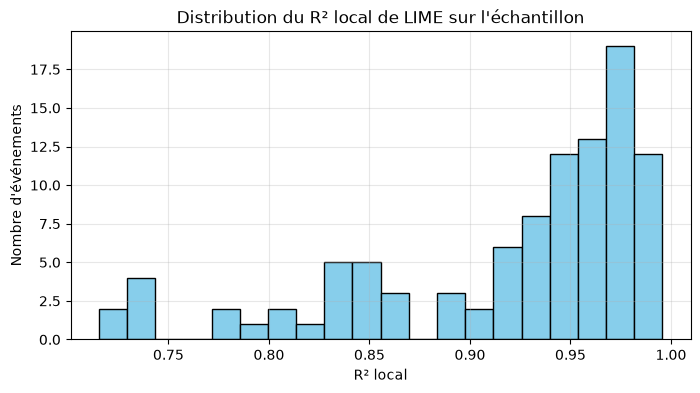

In [79]:
# 1. Affichage du résumé statistique dans la console
print("--- Statistiques du R² local ---")
print(df_lime["r2_local"].describe())

# 2. Affichage propre de l'histogramme
plt.figure(figsize=(8, 4))
df_lime["r2_local"].hist(bins=20, edgecolor="black", color="skyblue")
plt.title("Distribution du R² local de LIME sur l'échantillon")
plt.xlabel("R² local")
plt.ylabel("Nombre d'événements")
plt.grid(True, alpha=0.3)
#plt.savefig("R2 local.png", dpi=150, bbox_inches="tight")
#Image("R2 local.png")

The local R2 scores are very high, that leads us to do the overfitting tests (see step4 function with efective_n and r2_holdout).

## Analysis of our results / searching for interpretation

Now we want to apply data analysis methods to the coefs of our events to see if we can deduce something from the explanations of our Unet model. 

In [35]:
# On nettoie d'abord notre jeu de données pour ne pas tout garder.

df=df_lime[df_lime["r2_local"] >= 0.5]
feature_names = [c for c in df.columns if "__forcing_reel__" in c]
print(f"{len(df)} / {len(df_lime)} events conservés après filtre R²")
"standard_deviation" in df_lime.columns

100 / 100 events conservés après filtre R²


True

In [36]:
#On standardise maintenant nos données (on n'a pas besoin de centrer, on réduit uniquement).
df[feature_names]=df[feature_names].div(df["standard_deviation"], axis=0)

In [37]:
df.groupby("saison")["severite_pic"].describe()

,count,mean,std,min,25%,50%,75%,max
saison,,,,,,,,
Automne,25.0,1.182744,0.092945,1.048452,1.120950,1.174784,1.214936,1.446301
Hiver,25.0,1.209692,0.144821,1.060223,1.117794,1.147501,1.254618,1.641953
Printemps,25.0,1.172188,0.083098,1.057319,1.135645,1.162688,1.185753,1.401274
Été,25.0,1.260772,0.126837,1.071018,1.180438,1.229623,1.302740,1.609327


<Axes: >

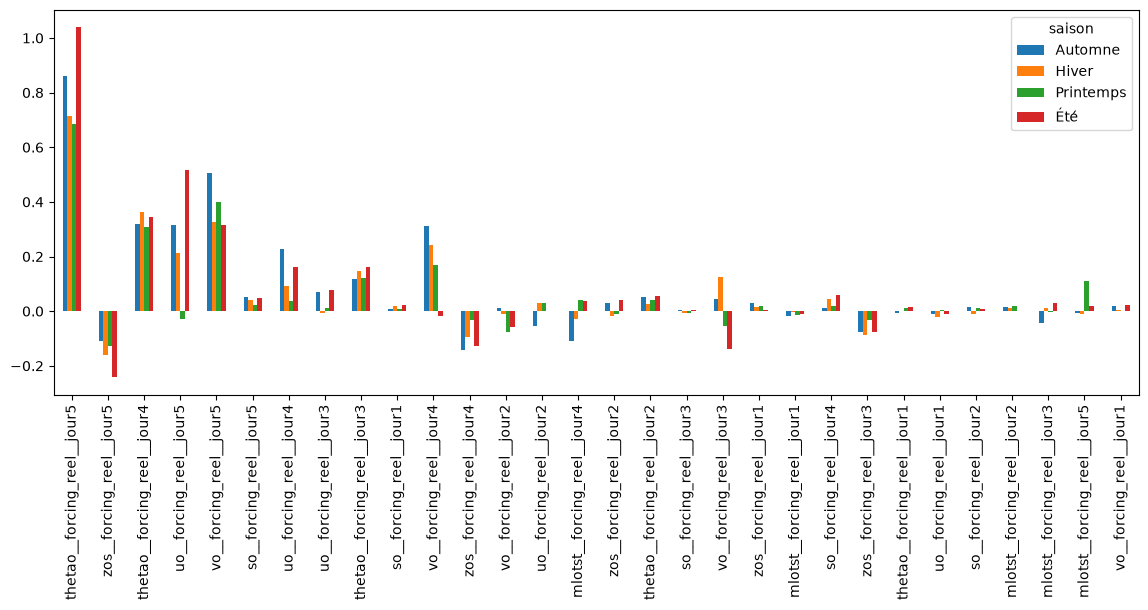

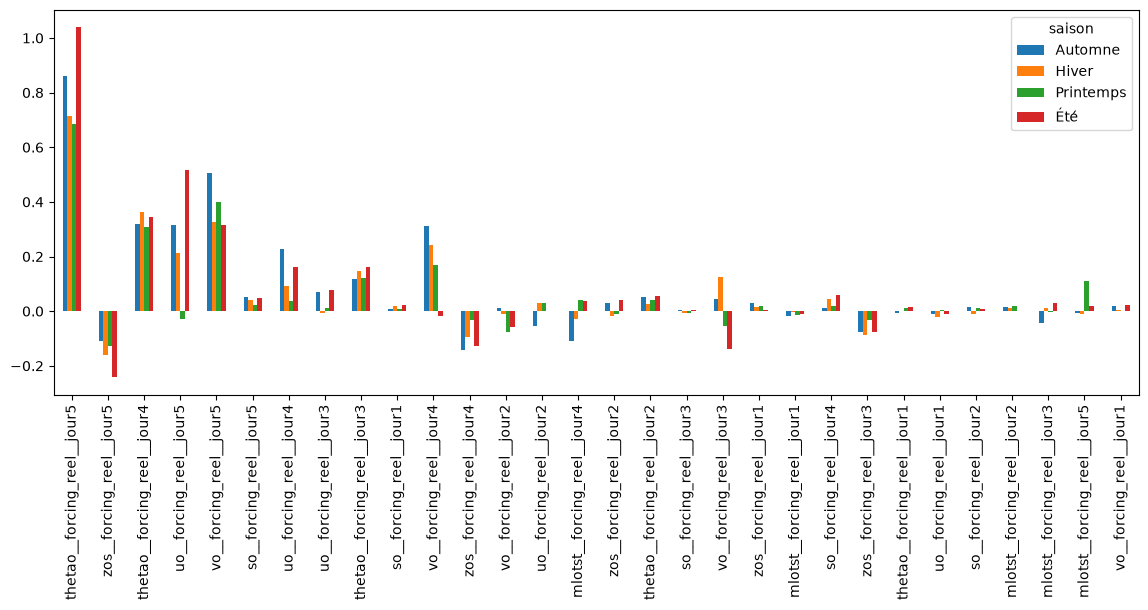

In [39]:
%matplotlib inline
means_by_saison = df.groupby("saison")[feature_names].mean()
means_by_saison.T.plot(kind="bar", figsize=(14,5))

On voit que : 
* les variables du jour 5 sont prédominentes : dès qu'on s'éloigne, les coefficients s'effondrent. la trajectoire du modèle s'appuie peu sur les forçages distants
* Les variables les plus importantes sont thetao, ssh et les courants de surface. (avec une grande majorité pour la sst)
* il semble y avoir un effet saisonnier marqué sur la température.

On va à présent vérifier par un test statistique qu'il y a une différence par saison sur la distribution de thetao : 
On utilise le test de Kruskal-Wallis. "Il généralise le test de Wilcoxon-Mann-Whitney, qui est utilisé pour comparer seulement deux groupes. L'équivalent paramétrique du test de Kruskal-Wallis est l'analyse de la variance (ANOVA) à un facteur." (wikipedia)

In [46]:
from scipy.stats import kruskal
groups = [df[df["saison"]==s]["thetao__forcing_reel__jour5"] for s in df["saison"].unique()]
print(kruskal(*groups))

groups = [df[df["saison"]==s]["uo__forcing_reel__jour5"] for s in df["saison"].unique()]
print(kruskal(*groups))

KruskalResult(statistic=np.float64(2.6659960396039537), pvalue=np.float64(0.44603687428687244))
KruskalResult(statistic=np.float64(8.686146534653403), pvalue=np.float64(0.03376831558744406))


Les données ne permettent pas de conclure que la différence entre les saisons pour le forçage de la température au jour 5 est significative ($p_value>0.05$). 
Par contre, les données ne permettent pas refuter l'hypothèse d'un effet saisonnier des courants ($p_value<0.05$)

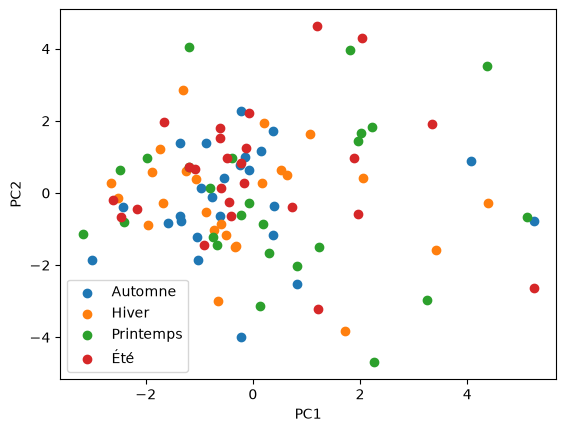

11.194937608567008 10.01289631101769




In [74]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

n_components=20
top_n=15
pca=PCA(n_components=20)
X_scaled = StandardScaler().fit_transform(df[feature_names])
coords = pca.fit_transform(X_scaled)
df["pca1"], df["pca2"] = coords[:,0], coords[:,1]

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100

for saison, g in df.groupby("saison"):
    plt.scatter(g["pca1"], g["pca2"], label=saison)
plt.legend(); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.show()

print(var_pc1, var_pc2)

fig, axes = plt.subplots(1, n_components, figsize=(6 * n_components, 6))
explained = pca.explained_variance_ratio_ * 100

for i, (ax, comp) in enumerate(zip(axes[:2], pca.components_[:2])):
    loadings = pd.Series(comp, index=feature_names)
    top = loadings.abs().nlargest(top_n).index
    loadings[top].sort_values().plot(kind='barh', ax=ax, color='steelblue')
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'PC{i+1} ({explained[i]:.1f}%) — top {top_n} variables')
    ax.set_xlabel('Contribution à la composante')
    ax.grid(True, axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

([<matplotlib.axis.XTick at 0x7f7d78e96350>,
 [Text(0, 0, '0'),
  Text(1, 0, '1'),
  Text(2, 0, '2'),
  Text(3, 0, '3'),
  Text(4, 0, '4'),
  Text(5, 0, '5'),
  Text(6, 0, '6'),
  Text(7, 0, '7'),
  Text(8, 0, '8'),
  Text(9, 0, '9'),
  Text(10, 0, '10'),
  Text(11, 0, '11'),
  Text(12, 0, '12'),
  Text(13, 0, '13'),
  Text(14, 0, '14'),
  Text(15, 0, '15'),
  Text(16, 0, '16'),
  Text(17, 0, '17'),
  Text(18, 0, '18'),
  Text(19, 0, '19'),
  Text(20, 0, '20')])

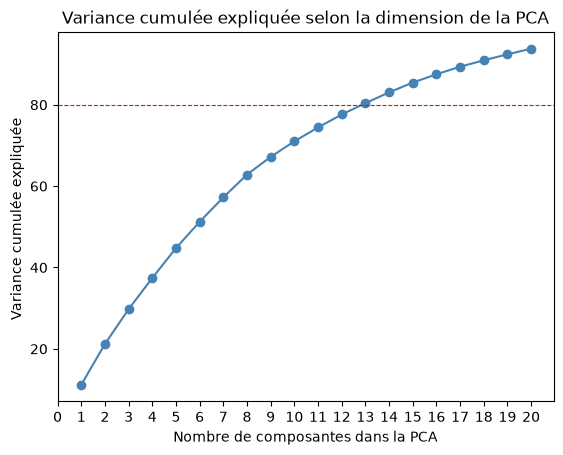

In [71]:
explained= pca.explained_variance_ratio_ * 100
cumulative = np.cumsum(explained)
plt.plot(range(1, len(explained)+1), cumulative, marker='o', color='steelblue')
plt.title('Variance cumulée expliquée selon la dimension de la PCA')
plt.xlabel('Nombre de composantes dans la PCA')
plt.ylabel('Variance cumulée expliquée ')
plt.axhline(80, color='red', linestyle='--', linewidth=0.8, label='Seuil 80%')
plt.xticks(range(0, len(explained) + 1))

On remarque que les deux premières composantes n'expliquent qu'une petite partie de la variance (Variance expliquée cumulée = 21,2%) et il faut 13 composantes pour expliquer 80% de la variance. (attention à l'interprétation)

Sur la projection des events sur les deux premiers axes, on n'observe aucune séparation visible lorsque l'on ajoute les saisons comme variable supplémentaire. 

=> on ne peut donc a priori rien conclure de cette ACP.

Si on essaie d'interpréter les axes : 
* PC1 oppose zos à thetao/vo
* PC2 est dominé par so, uo, mlotst

On essaie tout de même d'appliquer un clustering k-means sur les 30 features normalisées, pour voir ce que cela donne :

In [75]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# X_scaled : les 30 features normalisées (déjà centrées-réduites, PAS la PCA)
X_scaled = StandardScaler().fit_transform(df[feature_names])

# Test de plusieurs k pour trouver le nombre de clusters le plus net
scores = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    score = silhouette_score(X_scaled, km.labels_)
    scores.append((k, score))
    print(f"k={k} : silhouette = {score:.3f}")

k=2 : silhouette = 0.163
k=3 : silhouette = 0.142
k=4 : silhouette = 0.080
k=5 : silhouette = 0.037
k=6 : silhouette = 0.059
k=7 : silhouette = 0.040


On obtient des scores silhouettes très faibles (le meilleur, k=2, score de 0.163), on est donc dans une situation avec des clusters faiblement définis : pas adaptés.
Cela peut s'expliquer par le fait que l'on soit dans une zone géographique très restreinte, donc même climat, mêmes phénomènes physiques ? Il pourrait être intéressant de tester dans un cas plus global (sans parler de global, au moins sur une grande partie de l'atlantique nord ?)

Cependant, il n'y a pas uniquement les saisons qui peuvent créer des différences parmi les mhw : on peut penser à la sévérité ou à la localisation (bon, ça me parait limiter aussi car la sévérité de mes mhw reste très homogène sur ma zone et période temporelle. Je pourrais refaire une pca en superposant d'autres variables, je me laisse la possibilité si j'ai du temps à la fin mais cela me parait peu pertinent. 

In [77]:
plt.close('all')

Reste à faire : 
* essayer avec shap
* essayer avec lstm
* essayer avec une zone géographique plus grande / période de validation + grande.
* essayer en ajoutant le forçage atmosphérique dans mes variables explicatives